In [44]:
import numpy as np
from scipy.signal import butter, filtfilt, hilbert
from influxdb import InfluxDBClient
import operator
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from statsmodels.tsa.stattools import acf
from scipy.interpolate import interp1d
from scipy.optimize import minimize_scalar



def read_influx(influx, unit, table_name, data_name, start_timestamp, end_timestamp):
	if influx['ip'] == '127.0.0.1' or influx['ip'] == 'localhost':
		client = InfluxDBClient(influx['ip'], '8086', influx['user'], influx['passw'], influx['db'],  ssl=influx['ssl'])
	else:
		client = InfluxDBClient(influx['ip'].split('//')[1], '8086', influx['user'], influx['passw'], influx['db'],  ssl=influx['ssl'])
	query = 'SELECT "' + data_name + '" FROM "' + table_name + '" WHERE "location" = \''+unit+'\' AND time >= '+ str(int(start_timestamp*10e8))+' AND time < '+str(int(end_timestamp*10e8))
	result = client.query(query)
	points = list(result.get_points())
	values =  list(map(operator.itemgetter(data_name), points))
	times  =  list(map(operator.itemgetter('time'),  points))
	data = np.array(values)
	return data, times


def low_pass_filter(data, Fs, low, order):
    b, a = butter(order, low / (Fs * 0.5), 'low')
    if data.ndim == 1:
        N = len(data)
        padded = np.pad(data, (N, N), mode='reflect')
    elif data.ndim == 2:
        N = data.shape[1]
        padded = np.pad(data, ((0, 0), (N, N)), mode='reflect')
    filtered_data = filtfilt(b, a, padded)
    if data.ndim == 1:
        filtered_data = filtered_data[N:-N]
    elif data.ndim == 2:
        filtered_data = filtered_data[:, N:-N]
    return filtered_data


def normalize_signal(signal):
    mean = np.mean(signal)
    std = np.std(signal)
    if std > 0:
        return (signal - mean) / std
    else:
        return signal - mean


def get_bbi(sig, Fs=100, low=0.8):
    """
    Extract breath-to-breath intervals (BBI) from a 1D signal.
    Returns peak locations (in samples) and BBI array (in seconds).
    """
    # low-pass filter
    s = low_pass_filter(sig, Fs, low, order=3)
    # estimate dominant breathing period via ACF
    acf_vals = acf(s, nlags=Fs * 30, fft=True)
    acf_peaks, _ = find_peaks(acf_vals, distance=Fs * 2)
    if len(acf_peaks) > 0:
        period_samples = acf_peaks[0]  # first ACF peak = dominant period
    else:
        period_samples = Fs * 4  # fallback ~4s

    # find breathing peaks with minimum distance = 0.6 * estimated period
    min_dist = int(period_samples * 0.6)
    peaks, _ = find_peaks(s, distance=min_dist,
                          height=np.mean(s) + 0.3 * np.std(s))
    bbi = np.diff(peaks) / Fs  # in seconds
    # midpoint timestamps for plotting (in seconds)
    bbi_times = (peaks[:-1] + np.diff(peaks) / 2) / Fs
    return peaks, bbi, bbi_times, s


def align_bbi_by_shift(bbi_times_bcg, bbi_bcg, bbi_times_ref, bbi_ref,
                       search_range=(-5.0, 5.0)):
    """
    Find the time shift (in seconds) that maximizes Pearson correlation
    between BCG BBI and REF BBI curves.

    Parameters
    ----------
    bbi_times_bcg, bbi_bcg : BBI time points and values from BCG
    bbi_times_ref, bbi_ref : BBI time points and values from REF (THO/ABD)
    search_range : (lo, hi) in seconds to search over

    Returns
    -------
    best_shift : float, optimal shift in seconds (positive = shift BCG right / BCG leads)
    best_corr  : float, Pearson r at optimal shift
    shifts     : array, all tested shifts
    corrs      : array, correlation at each shift
    """
    # build interpolators
    f_bcg = interp1d(bbi_times_bcg, bbi_bcg, kind='linear',
                     bounds_error=False, fill_value=np.nan)
    f_ref = interp1d(bbi_times_ref, bbi_ref, kind='linear',
                     bounds_error=False, fill_value=np.nan)

    # common time grid (unshifted)
    t_lo = max(bbi_times_bcg[0], bbi_times_ref[0]) + abs(search_range[0])
    t_hi = min(bbi_times_bcg[-1], bbi_times_ref[-1]) - abs(search_range[1])
    t_common = np.linspace(t_lo, t_hi, 300)
    ref_interp = f_ref(t_common)

    def neg_corr(shift):
        bcg_shifted = f_bcg(t_common + shift)
        valid = ~(np.isnan(bcg_shifted) | np.isnan(ref_interp))
        if valid.sum() < 5:
            return 0.0
        return -np.corrcoef(bcg_shifted[valid], ref_interp[valid])[0, 1]

    # brute-force scan + refine
    shifts = np.linspace(search_range[0], search_range[1], 500)
    corrs = np.array([-neg_corr(s) for s in shifts])

    best_idx = np.argmax(corrs)
    # refine around the peak
    res = minimize_scalar(neg_corr,
                          bounds=(shifts[max(0, best_idx-5)],
                                  shifts[min(len(shifts)-1, best_idx+5)]),
                          method='bounded')
    best_shift = res.x
    best_corr = -res.fun

    return best_shift, best_corr, shifts, corrs



influx_vitals_bsg = {'ip': 'https://sensorserver.engr.uga.edu', 'db': 'shake', 'user': 'algtest', 'passw': 'sensorweb711', 'ssl': True}
influx_vitals_sleep = {'ip': 'https://sensorserver.engr.uga.edu', 'db': 'sleeplab', 'user': 'algtest', 'passw': 'sensorweb711', 'ssl': True}
# id = 1
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom4/sleep-lab-tri-axis-monitoring-room-4?orgId=1&var-mac=b8:27:eb:64:49:4d&var-name=vitalsigns&from=1741590129135&to=1741590377579'
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom4/sleep-lab-tri-axis-monitoring-room-4?orgId=1&var-mac=b8:27:eb:64:49:4d&var-name=vitalsigns&from=1741578728950&to=1741578828373'

url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom3/sleep-lab-tri-axis-monitoring-room-3?orgId=1&var-mac=b8:27:eb:e0:9c:6f&var-name=vitalsigns&from=1741574712109&to=1741575001688'
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom3/sleep-lab-tri-axis-monitoring-room-3?orgId=1&var-mac=b8:27:eb:e0:9c:6f&var-name=vitalsigns&from=1741578680441&to=1741578963599'
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom3/sleep-lab-tri-axis-monitoring-room-3?orgId=1&var-mac=b8:27:eb:e0:9c:6f&var-name=vitalsigns&from=1741574692078&to=1741575119581'
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom3/sleep-lab-tri-axis-monitoring-room-3?orgId=1&var-mac=b8:27:eb:e0:9c:6f&var-name=vitalsigns&from=1741575672082&to=1741575973504'
url = 'https://sensorserver.engr.uga.edu:3000/d/BSGRS3dRoom3/sleep-lab-tri-axis-monitoring-room-3?orgId=1&var-mac=b8:27:eb:e0:9c:6f&var-name=vitalsigns&from=1741576576348&to=1741576877770'
mac = url.split('var-mac=')[1].split('&')[0]
start_time = int(int(url.split('from=')[1].split('&')[0]) / 1000)
end_time = int(int(url.split('to=')[1].split('&')[0]) / 1000)
room = url.split('/d/')[1].split('/')[0][-1]
if room == '2': Xaxis, Yaxis = 'E', 'N'
else: Xaxis, Yaxis = 'X', 'Y'

raw_X, _ = read_influx(influx_vitals_bsg, unit=mac, table_name=Xaxis, 
			data_name="value", start_timestamp=start_time, end_timestamp=end_time)
raw_Y, _ = read_influx(influx_vitals_bsg, unit=mac, table_name=Yaxis, 
			data_name="value", start_timestamp=start_time, end_timestamp=end_time)

tho, _ = read_influx(influx_vitals_sleep, unit=mac, table_name='SleepLab_test', 
			data_name="Effort THO", start_timestamp=start_time, end_timestamp=end_time)
abd, _ = read_influx(influx_vitals_sleep, unit=mac, table_name='SleepLab_test',
            data_name="Effort ABD", start_timestamp=start_time, end_timestamp=end_time)

# raw_X.shape, raw_Y.shape, raw_Z.shape, tho.shape, abd.shape

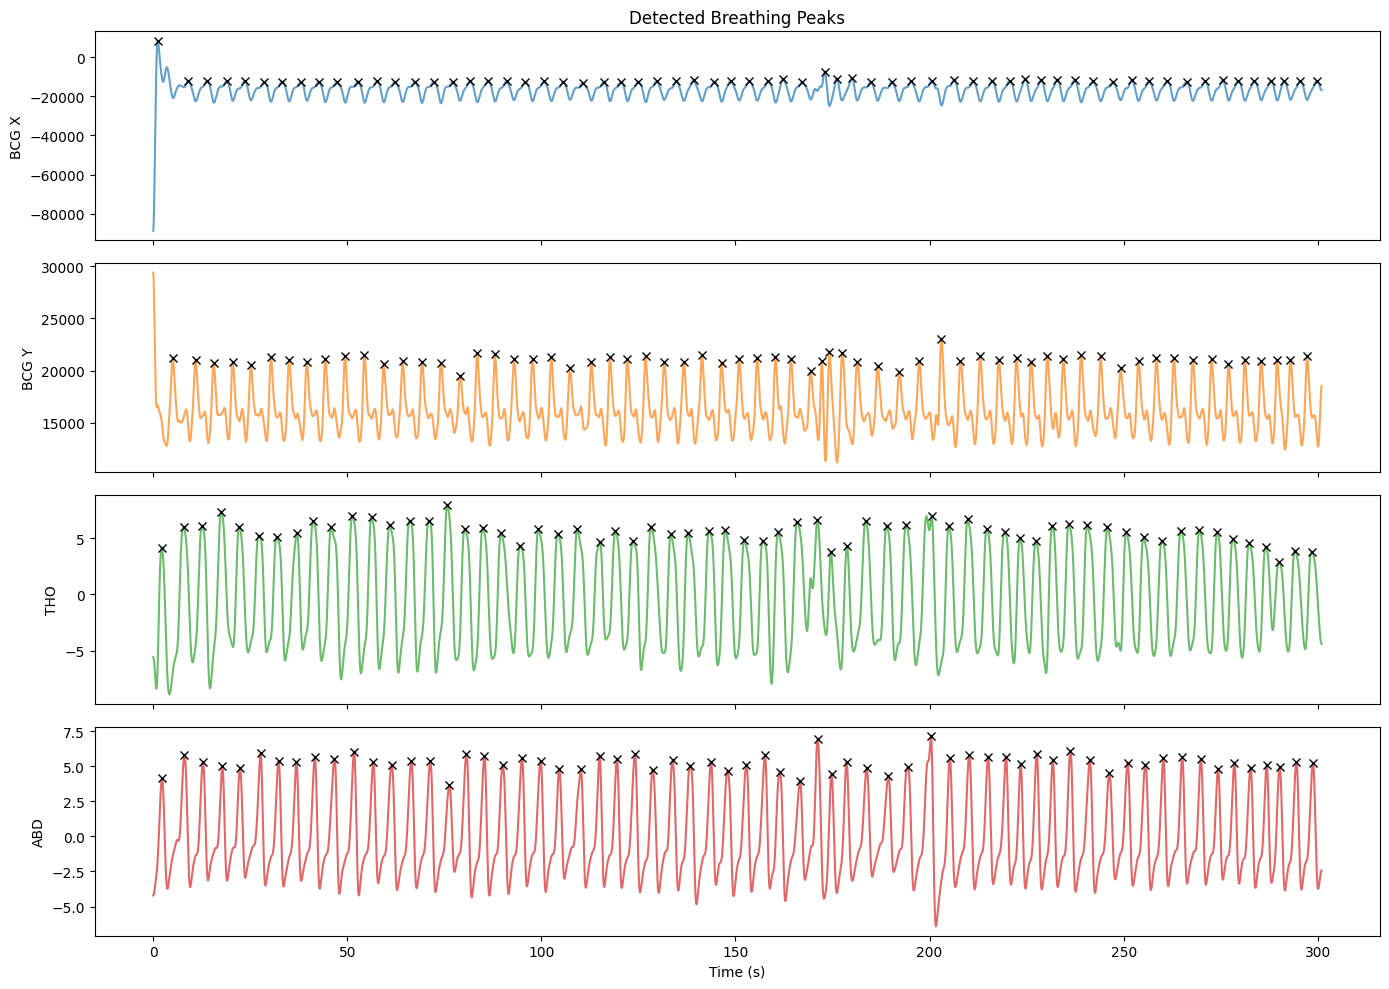

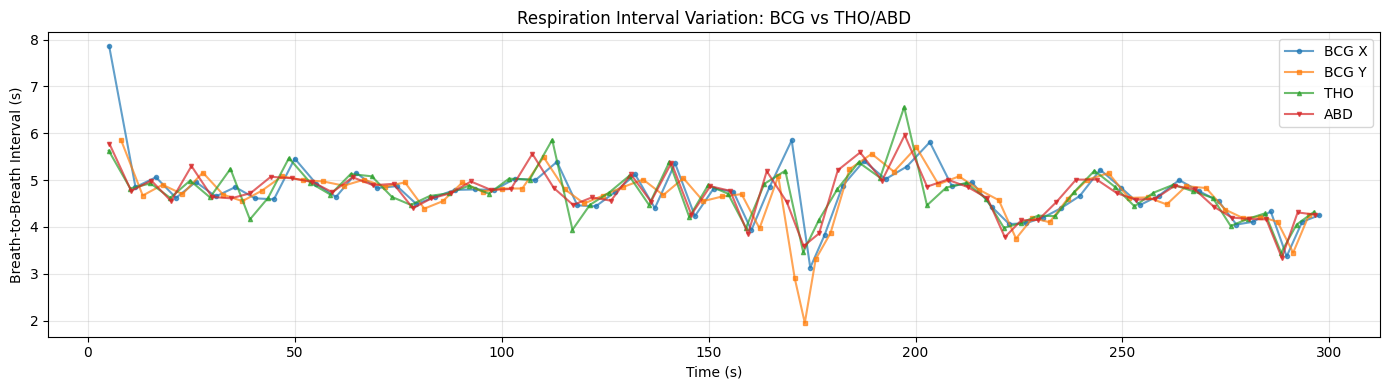

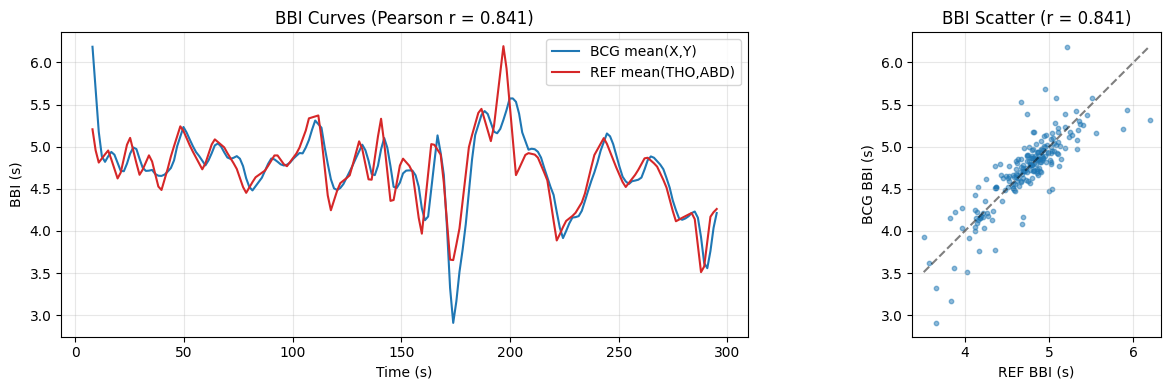

In [45]:
# --- Compute BBI for all 4 signals ---
peaks_x, bbi_x, t_x, filt_x = get_bbi(raw_X)
peaks_y, bbi_y, t_y, filt_y = get_bbi(raw_Y)
peaks_tho, bbi_tho, t_tho, filt_tho = get_bbi(tho, low=0.8)
peaks_abd, bbi_abd, t_abd, filt_abd = get_bbi(abd, low=0.8)

# --- Plot 1: filtered signals with detected peaks ---
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, s, pk, name, color in zip(axes,
    [filt_x, filt_y, filt_tho, filt_abd],
    [peaks_x, peaks_y, peaks_tho, peaks_abd],
    ['BCG X', 'BCG Y', 'THO', 'ABD'],
    ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    t = np.arange(len(s)) / 100
    ax.plot(t, s, color=color, alpha=0.7)
    ax.plot(pk / 100, s[pk], 'kx', markersize=6)
    ax.set_ylabel(name)
axes[-1].set_xlabel('Time (s)')
axes[0].set_title('Detected Breathing Peaks')
plt.tight_layout()
plt.show()

# --- Plot 2: BBI curves overlaid ---
fig, ax = plt.subplots(1, 1, figsize=(14, 4))
ax.plot(t_x, bbi_x, 'o-', label='BCG X', alpha=0.7, markersize=3)
ax.plot(t_y, bbi_y, 's-', label='BCG Y', alpha=0.7, markersize=3)
ax.plot(t_tho, bbi_tho, '^-', label='THO', alpha=0.7, markersize=3)
ax.plot(t_abd, bbi_abd, 'v-', label='ABD', alpha=0.7, markersize=3)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Breath-to-Breath Interval (s)')
ax.set_title('Respiration Interval Variation: BCG vs THO/ABD')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plot 3: BCG mean vs THO/ABD mean ---
# Interpolate all BBI to a common time grid for direct comparison
from scipy.interpolate import interp1d
t_min = max(t_x[0], t_y[0], t_tho[0], t_abd[0])
t_max = min(t_x[-1], t_y[-1], t_tho[-1], t_abd[-1])
t_common = np.linspace(t_min, t_max, 200)

bbi_x_interp = interp1d(t_x, bbi_x, kind='linear', fill_value='extrapolate')(t_common)
bbi_y_interp = interp1d(t_y, bbi_y, kind='linear', fill_value='extrapolate')(t_common)
bbi_tho_interp = interp1d(t_tho, bbi_tho, kind='linear', fill_value='extrapolate')(t_common)
bbi_abd_interp = interp1d(t_abd, bbi_abd, kind='linear', fill_value='extrapolate')(t_common)

bbi_bcg_mean = (bbi_x_interp + bbi_y_interp) / 2
bbi_ref_mean = (bbi_tho_interp + bbi_abd_interp) / 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_common, bbi_bcg_mean, label='BCG mean(X,Y)', color='tab:blue')
axes[0].plot(t_common, bbi_ref_mean, label='REF mean(THO,ABD)', color='tab:red')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('BBI (s)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
corr = np.corrcoef(bbi_bcg_mean, bbi_ref_mean)[0, 1]
axes[0].set_title(f'BBI Curves (Pearson r = {corr:.3f})')

axes[1].scatter(bbi_ref_mean, bbi_bcg_mean, alpha=0.5, s=10)
axes[1].plot([bbi_ref_mean.min(), bbi_ref_mean.max()],
             [bbi_ref_mean.min(), bbi_ref_mean.max()], 'k--', alpha=0.5)
axes[1].set_xlabel('REF BBI (s)')
axes[1].set_ylabel('BCG BBI (s)')
axes[1].set_title(f'BBI Scatter (r = {corr:.3f})')
axes[1].set_aspect('equal')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


BCG_X vs THO:  shift = +1.843 s,  r = 0.883
BCG_X vs ABD:  shift = +2.059 s,  r = 0.883
BCG_Y vs THO:  shift = +0.706 s,  r = 0.733
BCG_Y vs ABD:  shift = +2.007 s,  r = 0.856


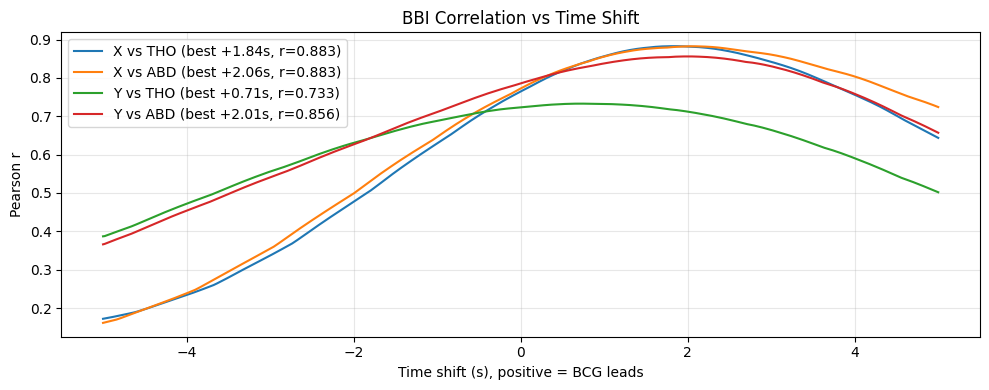


Mean optimal shift: +1.654 s (+165.4 samples @ 100Hz)


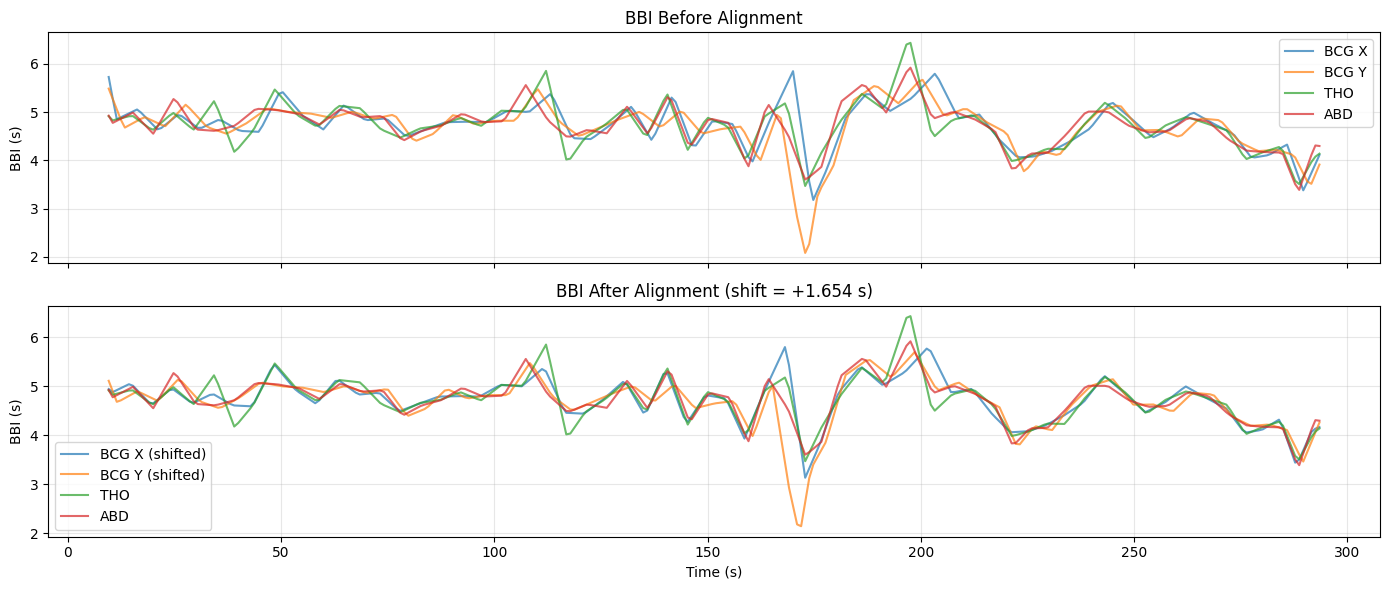

In [46]:
# --- Align BCG X vs THO ---
shift_x_tho, corr_x_tho, shifts, corrs_x_tho = align_bbi_by_shift(t_x, bbi_x, t_tho, bbi_tho)
shift_x_abd, corr_x_abd, _, corrs_x_abd = align_bbi_by_shift(t_x, bbi_x, t_abd, bbi_abd)
shift_y_tho, corr_y_tho, _, corrs_y_tho = align_bbi_by_shift(t_y, bbi_y, t_tho, bbi_tho)
shift_y_abd, corr_y_abd, _, corrs_y_abd = align_bbi_by_shift(t_y, bbi_y, t_abd, bbi_abd)

print(f"BCG_X vs THO:  shift = {shift_x_tho:+.3f} s,  r = {corr_x_tho:.3f}")
print(f"BCG_X vs ABD:  shift = {shift_x_abd:+.3f} s,  r = {corr_x_abd:.3f}")
print(f"BCG_Y vs THO:  shift = {shift_y_tho:+.3f} s,  r = {corr_y_tho:.3f}")
print(f"BCG_Y vs ABD:  shift = {shift_y_abd:+.3f} s,  r = {corr_y_abd:.3f}")

# --- Plot: correlation vs shift ---
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(shifts, corrs_x_tho, label=f'X vs THO (best {shift_x_tho:+.2f}s, r={corr_x_tho:.3f})')
ax.plot(shifts, corrs_x_abd, label=f'X vs ABD (best {shift_x_abd:+.2f}s, r={corr_x_abd:.3f})')
ax.plot(shifts, corrs_y_tho, label=f'Y vs THO (best {shift_y_tho:+.2f}s, r={corr_y_tho:.3f})')
ax.plot(shifts, corrs_y_abd, label=f'Y vs ABD (best {shift_y_abd:+.2f}s, r={corr_y_abd:.3f})')
ax.set_xlabel('Time shift (s), positive = BCG leads')
ax.set_ylabel('Pearson r')
ax.set_title('BBI Correlation vs Time Shift')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Plot: BBI after alignment (use mean shift) ---
best_shift = np.mean([shift_x_tho, shift_x_abd, shift_y_tho, shift_y_abd])
print(f"\nMean optimal shift: {best_shift:+.3f} s ({best_shift * 100:+.1f} samples @ 100Hz)")

f_bcg_x = interp1d(t_x, bbi_x, kind='linear', bounds_error=False, fill_value=np.nan)
f_bcg_y = interp1d(t_y, bbi_y, kind='linear', bounds_error=False, fill_value=np.nan)
f_tho = interp1d(t_tho, bbi_tho, kind='linear', bounds_error=False, fill_value=np.nan)
f_abd = interp1d(t_abd, bbi_abd, kind='linear', bounds_error=False, fill_value=np.nan)

t_lo = max(t_x[0], t_y[0], t_tho[0], t_abd[0]) + abs(best_shift)
t_hi = min(t_x[-1], t_y[-1], t_tho[-1], t_abd[-1]) - abs(best_shift)
t_common = np.linspace(t_lo, t_hi, 300)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
# Before shift
axes[0].plot(t_common, f_bcg_x(t_common), label='BCG X', alpha=0.7)
axes[0].plot(t_common, f_bcg_y(t_common), label='BCG Y', alpha=0.7)
axes[0].plot(t_common, f_tho(t_common), label='THO', alpha=0.7)
axes[0].plot(t_common, f_abd(t_common), label='ABD', alpha=0.7)
axes[0].set_title('BBI Before Alignment')
axes[0].set_ylabel('BBI (s)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# After shift
axes[1].plot(t_common, f_bcg_x(t_common + best_shift), label='BCG X (shifted)', alpha=0.7)
axes[1].plot(t_common, f_bcg_y(t_common + best_shift), label='BCG Y (shifted)', alpha=0.7)
axes[1].plot(t_common, f_tho(t_common), label='THO', alpha=0.7)
axes[1].plot(t_common, f_abd(t_common), label='ABD', alpha=0.7)
axes[1].set_title(f'BBI After Alignment (shift = {best_shift:+.3f} s)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('BBI (s)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


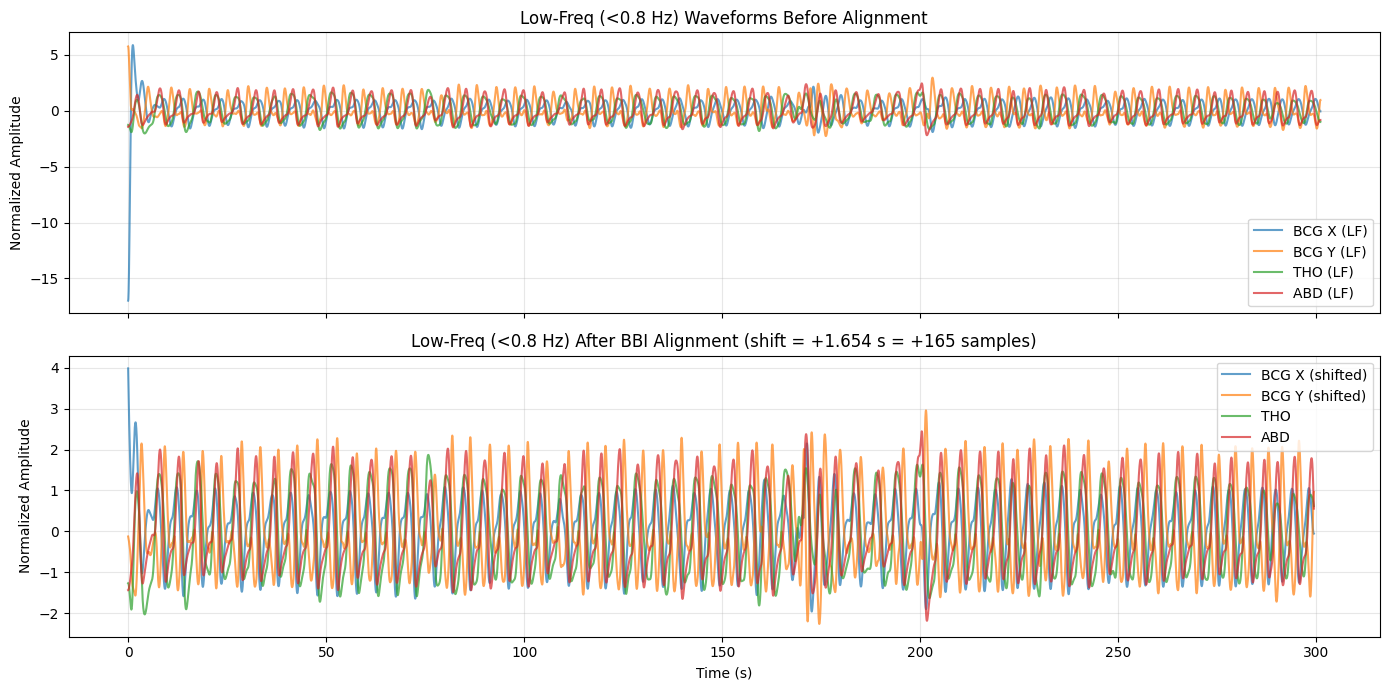

In [47]:
# --- Plot aligned low-frequency waveforms (X, Y, THO, ABD) using BBI-derived shift ---
Fs = 100
low_cut = 0.8
shift_samples = int(round(best_shift * Fs))

# Extract low-frequency components
lf_x = normalize_signal(low_pass_filter(raw_X, Fs, low_cut, order=3))
lf_y = normalize_signal(low_pass_filter(raw_Y, Fs, low_cut, order=3))
lf_tho = normalize_signal(low_pass_filter(tho, Fs, low_cut, order=3))
lf_abd = normalize_signal(low_pass_filter(abd, Fs, low_cut, order=3))

N = len(lf_x)
if shift_samples > 0:
    bcg_x_aligned = lf_x[shift_samples:]
    bcg_y_aligned = lf_y[shift_samples:]
    tho_aligned = lf_tho[:N - shift_samples]
    abd_aligned = lf_abd[:N - shift_samples]
elif shift_samples < 0:
    s = abs(shift_samples)
    bcg_x_aligned = lf_x[:N - s]
    bcg_y_aligned = lf_y[:N - s]
    tho_aligned = lf_tho[s:]
    abd_aligned = lf_abd[s:]
else:
    bcg_x_aligned = lf_x
    bcg_y_aligned = lf_y
    tho_aligned = lf_tho
    abd_aligned = lf_abd

t_orig = np.arange(N) / Fs
t_aligned = np.arange(len(bcg_x_aligned)) / Fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Before alignment
axes[0].plot(t_orig, lf_x, label='BCG X (LF)', alpha=0.7)
axes[0].plot(t_orig, lf_y, label='BCG Y (LF)', alpha=0.7)
axes[0].plot(t_orig, lf_tho, label='THO (LF)', alpha=0.7, linewidth=1.5)
axes[0].plot(t_orig, lf_abd, label='ABD (LF)', alpha=0.7, linewidth=1.5)
axes[0].set_title(f'Low-Freq (<{low_cut} Hz) Waveforms Before Alignment')
axes[0].set_ylabel('Normalized Amplitude')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# After alignment
axes[1].plot(t_aligned, bcg_x_aligned, label='BCG X (shifted)', alpha=0.7)
axes[1].plot(t_aligned, bcg_y_aligned, label='BCG Y (shifted)', alpha=0.7)
axes[1].plot(t_aligned, tho_aligned, label='THO', alpha=0.7, linewidth=1.5)
axes[1].plot(t_aligned, abd_aligned, label='ABD', alpha=0.7, linewidth=1.5)
axes[1].set_title(f'Low-Freq (<{low_cut} Hz) After BBI Alignment (shift = {best_shift:+.3f} s = {shift_samples:+d} samples)')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Normalized Amplitude')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
